<a href="https://colab.research.google.com/github/abbyhendricks03-hash/special-octo-memory/blob/main/PerformanceII.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Enter Wing Geometry & Aerodynamic Inputs ---
Wing Span b (ft): 44
Tip Chord ct (ft): 2.5
Root Chord cr (ft): 5
Leading Edge Sweep Angle (deg): 2
Airfoil Lift Curve Slope a0 (1/deg): 0.108
Airfoil/Wing Zero Lift Angle (deg): -4
Swet - 2S (ft^2): 600
Cfe: 0.0045
Planform Area S             = 165.000000 ft²
Aspect Ratio AR             = 11.733333
Taper Ratio λ               = 0.500000
Sweep Angles: Λ0.25 = 0.373086 deg, Λ0.50 = -1.254429 deg, Λ0.70 = -2.555111 deg
Mean Aerodynamic Chord Cmac = 3.888889 ft
Span Efficiency Factor e    = 0.975062
Lift Curve Slope a          = 0.092137 1/deg
Zero-Lift Drag CDo          = 0.025364
Induced Drag Factor K       = 0.037097

--- Enter Steady Level Flight Analysis Inputs ---
Shaft Power Ps (hp): 350
Constant Efficiency eta_pr: 0.82
Aircraft Weight W (lbs): 7000
Propeller RPM: 2700
Propeller Diameter D (inches): 76
Air Density rho (lbs/ft³): 0.002377


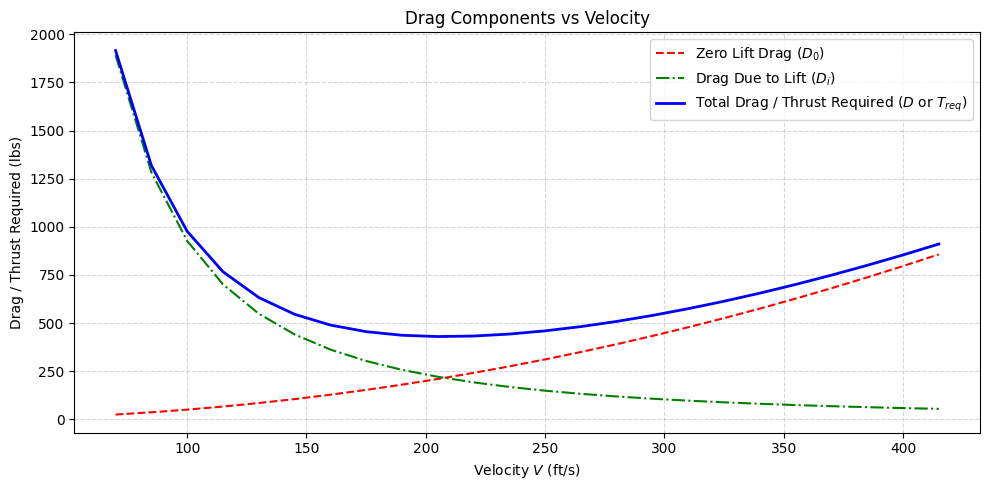

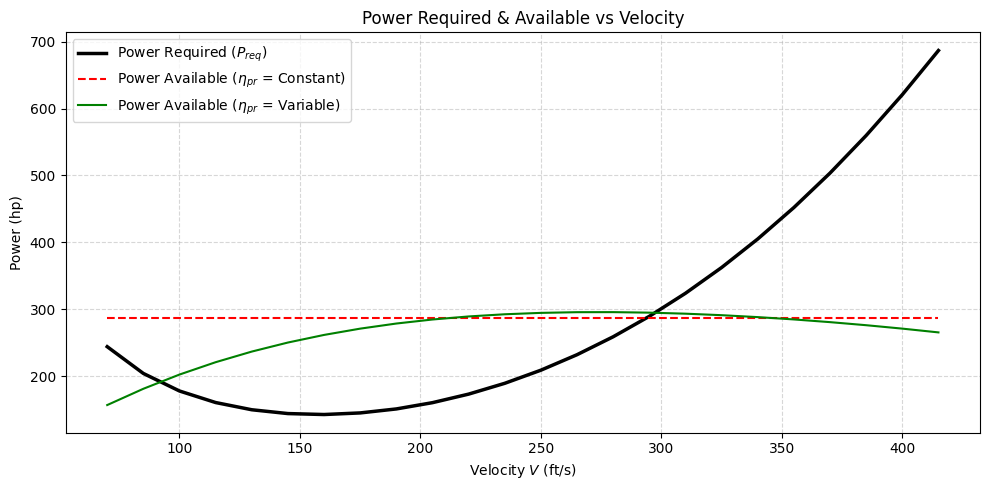

In [ ]:
import numpy as np
import math
import matplotlib.pyplot as plt

# =====================================================================
# Performance I
# =====================================================================
print("--- Enter Wing Geometry & Aerodynamic Inputs ---")
b = float(input("Wing Span b (ft): "))
ct = float(input("Tip Chord ct (ft): "))
cr = float(input("Root Chord cr (ft): "))
sweep_le = float(input("Leading Edge Sweep Angle (deg): "))
a0 = float(input("Airfoil Lift Curve Slope a0 (1/deg): "))
alpha_L0 = float(input("Airfoil/Wing Zero Lift Angle (deg): "))
swet_minus_2S = float(input("Swet - 2S (ft^2): "))
Cfe = float(input("Cfe: "))

# Calculations
lam = ct / cr
S = 0.5 * (cr + ct) * b
AR = b**2 / S

def sweep_at_x(x, sweep_le_deg, AR, lam):
    term = np.tan(np.radians(sweep_le_deg))
    correction = (4 / AR) * (x * ((1 - lam) / (1 + lam)))
    return np.degrees(np.arctan(term - correction))

Lambda_025 = sweep_at_x(0.25, sweep_le, AR, lam)
Lambda_050 = sweep_at_x(0.50, sweep_le, AR, lam)
Lambda_070 = sweep_at_x(0.70, sweep_le, AR, lam)
Cmac = (2/3) * cr * ((1 + lam + lam**2) / (1 + lam))

delta = (
    (-0.401*AR + 6.6421)*lam**6
    + (1.2357*AR - 22.276)*lam**5
    + (-1.4102*AR + 29.161)*lam**4
    + (0.6687*AR - 18.733)*lam**3
    + (-0.0332*AR + 6.008)*lam**2
    + (-0.0592*AR - 0.8514)*lam
    + (0.0128*AR + 0.029)
)
e = 1 / (1 + delta)
a0_rad = a0 * (180 / math.pi)
a = a0_rad / (1 + (a0_rad / (math.pi * e * AR)))
a_deg = a * (math.pi / 180)
Swet = swet_minus_2S + 2 * S
Swet_S = Swet / S
CDo = Swet_S * Cfe
K3 = 1 / (math.pi * e * AR)
K1 = (1/3) * K3
K = K1 + K3

print(f"Planform Area S             = {S:.6f} ft²")
print(f"Aspect Ratio AR             = {AR:.6f}")
print(f"Taper Ratio λ               = {lam:.6f}")
print(f"Sweep Angles: Λ0.25 = {Lambda_025:.6f} deg, Λ0.50 = {Lambda_050:.6f} deg, Λ0.70 = {Lambda_070:.6f} deg")
print(f"Mean Aerodynamic Chord Cmac = {Cmac:.6f} ft")
print(f"Span Efficiency Factor e    = {e:.6f}")
print(f"Lift Curve Slope a          = {a_deg:.6f} 1/deg")
print(f"Zero-Lift Drag CDo          = {CDo:.6f}")
print(f"Induced Drag Factor K       = {K:.6f}")

# =====================================================================
# Performance II
# =====================================================================
print("\n--- Enter Steady Level Flight Analysis Inputs ---")
Ps = float(input("Shaft Power Ps (hp): "))
eta_pr = float(input("Constant Efficiency eta_pr: "))
W = float(input("Aircraft Weight W (lbs): "))
RPM_prop = float(input("Propeller RPM: "))
D_prop_in = float(input("Propeller Diameter D (inches): "))
rho = float(input("Air Density rho (lbs/ft³): "))

# Calculations using both new inputs & Part 1 computed values (S, CDo, K, a_deg)
D_prop = D_prop_in / 12.0
N_prop = RPM_prop / 60.0
Ps_ft_lb_s = Ps * 550.0

# Velocity Range
V_range = np.arange(70, 415 + 15, 15)

q = 0.5 * rho * V_range**2
CL = W / (q * S)
alpha_wing = (CL / a_deg) + alpha_L0

CD_zero = CDo
CD_lift = K * CL**2
CD_total = CD_zero + CD_lift

D_zero = CD_zero * q * S
D_lift = CD_lift * q * S
Thrust_req = D_zero + D_lift

Preq_ft_lb_s = Thrust_req * V_range
Preq_hp = Preq_ft_lb_s / 550.0

eta_pr_const = eta_pr
Pavail_const_hp = Ps * eta_pr_const
Pavail_const_vector = np.full_like(V_range, Pavail_const_hp)

J = V_range / (N_prop * D_prop)
eta_pr_actual = -0.1915 * J**4 + 1.0438 * J**3 - 2.4071 * J**2 + 2.414 * J - 0.0152
eta_pr_actual = np.clip(eta_pr_actual, 0.0, 1.0)
Pavail_actual_hp = Ps * eta_pr_actual

# Graphs
plt.figure(figsize=(10, 5))
plt.plot(V_range, D_zero, 'r--', label=r'Zero Lift Drag ($D_{0}$)')
plt.plot(V_range, D_lift, 'g-.', label=r'Drag Due to Lift ($D_{i}$)')
plt.plot(V_range, Thrust_req, 'b-', linewidth=2, label=r'Total Drag / Thrust Required ($D$ or $T_{req}$)')
plt.title('Drag Components vs Velocity')
plt.xlabel('Velocity $V$ (ft/s)')
plt.ylabel('Drag / Thrust Required (lbs)')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(V_range, Preq_hp, 'k-', linewidth=2.5, label=r'Power Required ($P_{req}$)')
plt.plot(V_range, Pavail_const_vector, 'r--', label=r'Power Available ($\eta_{pr}$ = Constant)')
plt.plot(V_range, Pavail_actual_hp, 'g-', label=r'Power Available ($\eta_{pr}$ = Variable)')
plt.title('Power Required & Available vs Velocity')
plt.xlabel('Velocity $V$ (ft/s)')
plt.ylabel('Power (hp)')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()